# FGW: чувствительность к α на MBD и его зашумлённой копии

Ноутбук читает артефакты `cross_schema.testing_alpha.run`. Вычисление паспортов,
NMI и запуск matcher выполняются отдельно. На обеих сторонах — **те же строки MBD**;
столбцы копии переименованы и переставлены. Истинная карта известна только оценке.

По умолчанию: 
- α = 0, 0.1, …, 1; 
- (λ, p) = (0, 0), (0.15, 0.15), (0.30, 0.30),
(0, 0.15), (0.15, 0); 
- 3 seed для каждого шумного условия. 

Это **143 запуска FGW**.

```bash
PYTHONPATH=src python -m cross_schema.testing_alpha.run --mbd-root data/mbd --out-dir data/testing_alpha
```

Настройте `RESULTS` в следующей ячейке. Прерванный/идущий эксперимент тоже можно
посмотреть: учитываются только запуски с готовым `metrics.json`.


In [10]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
RESULTS = Path(
    os.environ.get("RESULTS_DIR", "/mnt/storage/d.tanyushkina/transactions/testing_alpha_143")
).expanduser()

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)
manifest = json.loads((RESULTS / 'manifest.json').read_text())
settings = manifest['config']['settings']
case_table = pd.DataFrame(manifest['cases'])
records = [json.loads(p.read_text()) for p in sorted((RESULTS / 'cases').rglob('metrics.json'))]
if not records:
    raise RuntimeError(f'В {RESULTS} ещё нет завершённых запусков FGW.')
runs = pd.DataFrame(records).sort_values(['condition', 'noise_seed', 'alpha'], na_position='first')
if runs.duplicated(['case_id', 'alpha']).any():
    raise ValueError('Повторяются case_id + alpha; проверьте каталог результатов.')

print(f"Завершено {len(runs)} / {manifest['expected_runs']} запусков FGW")
print(f"Фактически выполнено инициализаций: {int(runs.optimizer_starts.sum())}")
display(case_table)
display(pd.Series({key: settings[key] for key in [
    'alphas', 'noise_seeds', 'sample_seed', 'permutation_seed', 'solver_seed',
    'sample_rows', 'structure_rows', 'n_init', 'max_iter', 'max_distance',
]}).rename('value').to_frame())


Завершено 143 / 143 запусков FGW
Фактически выполнено инициализаций: 715


,case_id,condition,numeric_noise,category_noise,noise_seed
0,clean,clean,0.00,0.00,NaN
1,mixed_015/seed_0,mixed_015,0.15,0.15,0.0
2,mixed_015/seed_1,mixed_015,0.15,0.15,1.0
3,mixed_015/seed_2,mixed_015,0.15,0.15,2.0
4,mixed_030/seed_0,mixed_030,0.30,0.30,0.0
5,mixed_030/seed_1,mixed_030,0.30,0.30,1.0
6,mixed_030/seed_2,mixed_030,0.30,0.30,2.0
7,categorical_015/seed_0,categorical_015,0.00,0.15,0.0
8,categorical_015/seed_1,categorical_015,0.00,0.15,1.0
9,categorical_015/seed_2,categorical_015,0.00,0.15,2.0


,value
alphas,"[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, ..."
noise_seeds,"[0, 1, 2]"
sample_seed,42
permutation_seed,42
solver_seed,42
sample_rows,2000000
structure_rows,200000
n_init,5
max_iter,300
max_distance,0.7


## 1. Полнота эксперимента и сходимость

Seed шума изменяет только данные. Seed оптимизатора фиксирован для всех α и копий.
Условия без шума не размножаются по seed. `NOT_CONVERGED` нельзя незаметно исключать
из усреднения: ниже такие результаты показаны и остаются в графиках.


In [11]:
expected = pd.MultiIndex.from_tuples(
    [(case['case_id'], float(alpha)) for case in manifest['cases'] for alpha in settings['alphas']],
    names=['case_id', 'alpha'],
)
observed = pd.MultiIndex.from_frame(runs[['case_id', 'alpha']])
missing = expected.difference(observed)
extra = observed.difference(expected)
print('Незавершённых комбинаций:', len(missing))
if len(missing):
    display(missing.to_frame(index=False))
if len(extra):
    raise ValueError(f'Найдены результаты вне manifest: {list(extra)}')
display(pd.crosstab(runs.condition, runs.status))
display(runs.loc[~runs.converged, ['case_id', 'alpha', 'status', 'fw_gap', 'accuracy', 'truth_filtered']])


Незавершённых комбинаций: 0


status,CONVERGED
condition,
categorical_015,33
clean,11
mixed_015,33
mixed_030,33
numeric_015,33


,case_id,alpha,status,fw_gap,accuracy,truth_filtered


## 2. Accuracy по α

`accuracy = число правильных соответствий / все 12 полей MBD`.
Незаполненные поля считаются ошибками. У `amount` только один кандидат числового
типа, поэтому **категориальная accuracy** более показательна.
Полоса на графике — минимум–максимум по seed, **не доверительный интервал**.


,condition,numeric_noise,category_noise,alpha,seeds,accuracy_mean,accuracy_sd,categorical_mean,categorical_sd,numeric_mean,coverage_mean,unfilled_mean,truth_filtered_mean
0,categorical_015,0.00,0.15,0.0,3,1.000000,0.000000,1.000000,0.000000,1.0,1.0,0.0,0.0
1,categorical_015,0.00,0.15,0.1,3,1.000000,0.000000,1.000000,0.000000,1.0,1.0,0.0,0.0
2,categorical_015,0.00,0.15,0.2,3,1.000000,0.000000,1.000000,0.000000,1.0,1.0,0.0,0.0
3,categorical_015,0.00,0.15,0.3,3,0.916667,0.000000,0.909091,0.000000,1.0,1.0,0.0,0.0
4,categorical_015,0.00,0.15,0.4,3,0.833333,0.000000,0.818182,0.000000,1.0,1.0,0.0,0.0
5,categorical_015,0.00,0.15,0.5,3,1.000000,0.000000,1.000000,0.000000,1.0,1.0,0.0,0.0
6,categorical_015,0.00,0.15,0.6,3,1.000000,0.000000,1.000000,0.000000,1.0,1.0,0.0,0.0
7,categorical_015,0.00,0.15,0.7,3,0.888889,0.096225,0.878788,0.104973,1.0,1.0,0.0,0.0
8,categorical_015,0.00,0.15,0.8,3,0.750000,0.000000,0.727273,0.000000,1.0,1.0,0.0,0.0
9,categorical_015,0.00,0.15,0.9,3,0.666667,0.000000,0.636364,0.000000,1.0,1.0,0.0,0.0


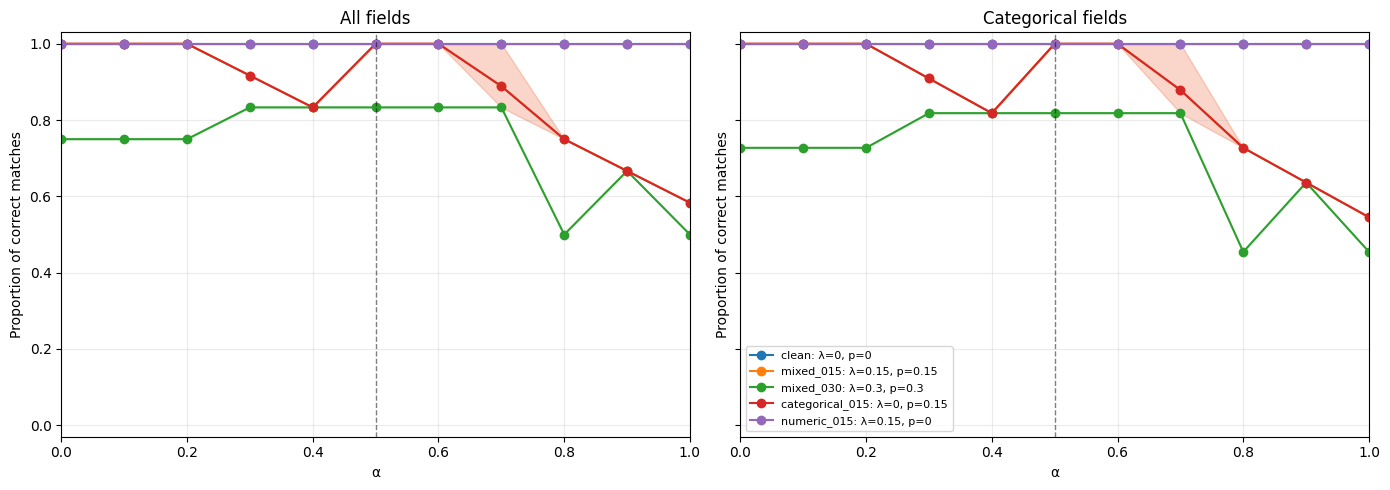

In [12]:
summary = runs.groupby(['condition', 'numeric_noise', 'category_noise', 'alpha'], sort=False).agg(
    seeds=('accuracy', 'size'),
    accuracy_mean=('accuracy', 'mean'), accuracy_sd=('accuracy', 'std'),
    categorical_mean=('categorical_accuracy', 'mean'), categorical_sd=('categorical_accuracy', 'std'),
    numeric_mean=('numeric_accuracy', 'mean'), coverage_mean=('coverage', 'mean'),
    unfilled_mean=('unfilled_rate', 'mean'), truth_filtered_mean=('truth_filtered', 'mean'),
).reset_index()
display(summary)

condition_order = list(manifest['config']['noise_levels'])
labels = {name: f"{name}: λ={values[0]:g}, p={values[1]:g}"
          for name, values in manifest['config']['noise_levels'].items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, metric, title in zip(axes, ['accuracy', 'categorical_accuracy'], ['All fields', 'Categorical fields']):
    for condition in condition_order:
        points = runs[runs.condition == condition].groupby('alpha')[metric].agg(['mean', 'min', 'max']).sort_index()
        if points.empty:
            continue
        x = points.index.to_numpy(dtype=float)
        line, = ax.plot(x, points['mean'].to_numpy(), marker='o', label=labels[condition])
        ax.fill_between(x, points['min'].to_numpy(), points['max'].to_numpy(), color=line.get_color(), alpha=0.12)
    ax.axvline(0.5, color='black', linewidth=1, linestyle='--', alpha=0.5)
    ax.set(title=title, xlabel='α', ylabel='Proportion of correct matches', ylim=(-0.03, 1.03), xlim=(0, 1))
    ax.grid(alpha=0.25)
axes[1].legend(loc='best', fontsize=8)
fig.tight_layout()
plt.show()


## 3. Незаполненные поля и фильтр кандидатов

Если истинная пара исключена фильтрами, никакое α её не восстановит.
Даже при α=1 остаются паспортный порог 0.70, типовые фильтры и tie-break по D.


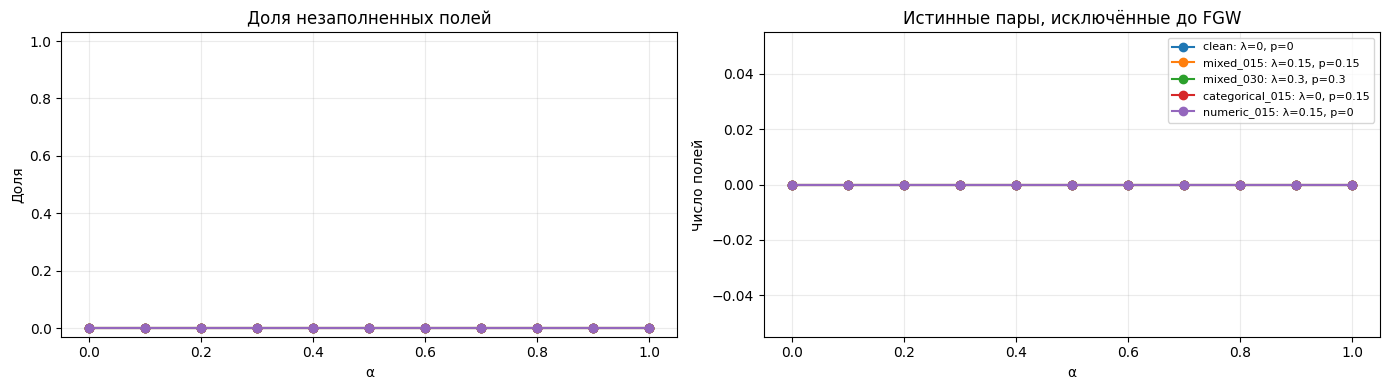

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for condition in condition_order:
    points = runs[runs.condition == condition].groupby('alpha')[['unfilled_rate', 'truth_filtered']].mean().sort_index()
    if points.empty:
        continue
    axes[0].plot(points.index, points.unfilled_rate, marker='o', label=labels[condition])
    axes[1].plot(points.index, points.truth_filtered, marker='o', label=labels[condition])
axes[0].set(title='Доля незаполненных полей', xlabel='α', ylabel='Доля', ylim=(-0.03, 1.03))
axes[1].set(title='Истинные пары, исключённые до FGW', xlabel='α', ylabel='Число полей')
for ax in axes:
    ax.grid(alpha=0.25)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


## 4. Какой шум действительно применился

Замены категорий равномерны среди **других** существующих значений. Нулевые суммы,
пропуски и константные поля сохраняются. `changed_fraction` считается среди ячеек,
которые можно изменить. Для числового поля с ненулевой λ эта доля обычно близка к 1;
силу искажения задаёт λ, а не эта доля.


In [14]:
audit_frames = []
for case in manifest['cases']:
    path = RESULTS / 'cases' / case['case_id'] / 'noise_audit.csv'
    if path.exists():
        audit_frames.append(pd.read_csv(path).assign(case_id=case['case_id']))
if audit_frames:
    noise_audit = pd.concat(audit_frames, ignore_index=True)
    display(noise_audit[['case_id', 'field', 'kind', 'scale', 'n_eligible', 'n_changed', 'changed_fraction', 'skip_reason']])
else:
    print('Диагностика шума ещё не записана.')
clean_profiles = pd.read_csv(RESULTS / 'clean_profile/profiles.csv')
display(clean_profiles)


,case_id,field,kind,scale,n_eligible,n_changed,changed_fraction,skip_reason
0,clean,amount,numeric,1.299420e+06,2000000,0,0.0,NaN
1,clean,event_type,categorical,NaN,2000000,0,0.0,NaN
2,clean,event_subtype,categorical,NaN,2000000,0,0.0,NaN
3,clean,currency,categorical,NaN,1999990,0,0.0,NaN
4,clean,src_type11,categorical,NaN,1989676,0,0.0,NaN
...,...,...,...,...,...,...,...,...
151,numeric_015/seed_2,dst_type12,categorical,NaN,1988237,0,0.0,NaN
152,numeric_015/seed_2,src_type21,categorical,NaN,1997923,0,0.0,NaN
153,numeric_015/seed_2,src_type22,categorical,NaN,1997923,0,0.0,NaN
154,numeric_015/seed_2,src_type31,categorical,NaN,1996502,0,0.0,NaN


,column,kind,n_rows,n_valid,null_share,n_unique,uniqueness,entropy_norm,top1_share,top3_share,min,max,mean,std,zero_share,q05,q25,q50,q75,q95,numeric_subtype,integer_share,quantile_scale,quantile_fallback,quantile_shape
0,amount,numeric,2000000,2000000,0.000000,1982723,0.991362,NaN,NaN,NaN,0.000005,3.205625e+11,1.499992e+06,2.965297e+08,0.0,84.215974,2819.874634,20875.672852,113486.285156,1299503.75,continuous,0.028206,1.299420e+06,none,"[-0.01606004951310297, -0.016000572819407203, ..."
1,event_type,categorical,2000000,2000000,0.000000,53,0.000027,0.562487,0.375430,0.619830,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,event_subtype,categorical,2000000,2000000,0.000000,60,0.000030,0.550601,0.372756,0.614851,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,currency,categorical,2000000,1999990,0.000005,11,0.000005,0.003290,0.999144,0.999887,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,src_type11,categorical,2000000,1989676,0.005162,54,0.000027,0.219991,0.785263,0.933299,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,src_type12,categorical,2000000,1989676,0.005162,210,0.000105,0.310379,0.623954,0.784150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,dst_type11,categorical,2000000,1988237,0.005881,49,0.000024,0.522462,0.306597,0.652509,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,dst_type12,categorical,2000000,1988237,0.005881,209,0.000105,0.453786,0.288116,0.546952,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,src_type21,categorical,2000000,1997923,0.001038,13724,0.006862,0.718939,0.101405,0.124467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,src_type22,categorical,2000000,1997923,0.001038,86,0.000043,0.798310,0.252785,0.355599,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Ошибки по конкретным полям

Среднее `correct` по seed для выбранного условия. Поля с совпадающими статистиками
или связями могут быть неразличимы; clean-контроль тоже не обязан давать 100%.


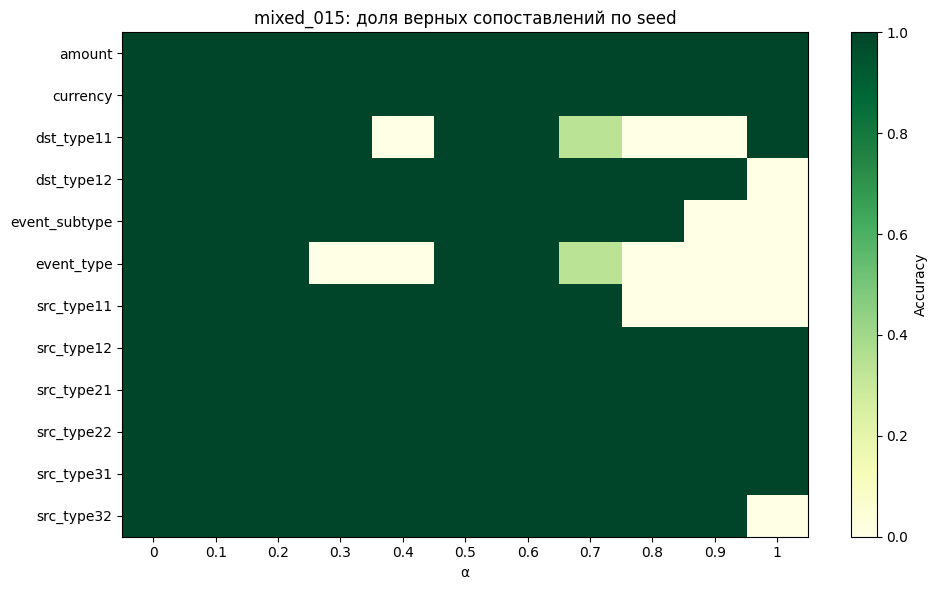

,case_id,alpha,mbd_field,truth,recovered,truth_allowed,candidate_count
37,categorical_015/seed_0,0.3,event_type,col_a10,col_a07,True,9
49,categorical_015/seed_0,0.4,event_type,col_a10,col_a07,True,9
54,categorical_015/seed_0,0.4,dst_type11,col_a02,col_a10,True,9
85,categorical_015/seed_0,0.7,event_type,col_a10,col_a07,True,9
90,categorical_015/seed_0,0.7,dst_type11,col_a02,col_a10,True,9
...,...,...,...,...,...,...,...
1310,mixed_030/seed_2,1.0,event_subtype,col_a07,col_a01,True,9
1312,mixed_030/seed_2,1.0,src_type11,col_a08,col_a07,True,9
1313,mixed_030/seed_2,1.0,src_type12,col_a06,col_a02,True,8
1314,mixed_030/seed_2,1.0,dst_type11,col_a02,col_a01,True,9


In [15]:
field_frames = []
for record in runs.to_dict('records'):
    frame = pd.read_csv(RESULTS / record['run_dir'] / 'recovery.csv')
    frame['condition'] = record['condition']
    frame['case_id'] = record['case_id']
    frame['noise_seed'] = record['noise_seed']
    frame['alpha'] = record['alpha']
    field_frames.append(frame)
fields = pd.concat(field_frames, ignore_index=True)
SELECTED_CONDITION = 'mixed_015'
if SELECTED_CONDITION not in set(fields.condition):
    SELECTED_CONDITION = runs.condition.iloc[0]
heat = fields[fields.condition == SELECTED_CONDITION].pivot_table(
    index='mbd_field', columns='alpha', values='correct', aggfunc='mean',
).sort_index(axis=1)
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(heat.to_numpy(dtype=float), vmin=0, vmax=1, cmap='YlGn', aspect='auto')
ax.set_xticks(range(len(heat.columns)), [f'{a:g}' for a in heat.columns])
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set(xlabel='α', title=f'{SELECTED_CONDITION}: доля верных сопоставлений по seed')
fig.colorbar(im, ax=ax, label='Accuracy')
fig.tight_layout()
plt.show()
display(fields.loc[~fields.correct, ['case_id', 'alpha', 'mbd_field', 'truth', 'recovered', 'truth_allowed', 'candidate_count']])


## 6. α=0.5 и максимум на этой сетке

Это описательное сравнение на том же синтетическом тесте. Максимум по сетке
не является результатом независимого выбора гиперпараметра. При трёх seed
не следует интерпретировать небольшую разницу как доказанное преимущество.


In [16]:
rows = []
for condition, group in runs.groupby('condition', sort=False):
    curve = group.groupby('alpha').accuracy.mean()
    best = float(curve.max())
    at_half = float(curve.loc[0.5]) if 0.5 in curve.index else np.nan
    rows.append({'condition': condition, 'accuracy_at_0.5': at_half,
                 'best_mean_accuracy': best, 'gap_from_best': best - at_half,
                 'alphas_tied_for_best': [float(a) for a, value in curve.items() if np.isclose(value, best)]})
display(pd.DataFrame(rows))


,condition,accuracy_at_0.5,best_mean_accuracy,gap_from_best,alphas_tied_for_best
0,categorical_015,1.000000,1.000000,0.0,"[0.0, 0.1, 0.2, 0.5, 0.6]"
1,clean,1.000000,1.000000,0.0,"[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, ..."
2,mixed_015,1.000000,1.000000,0.0,"[0.0, 0.1, 0.2, 0.5, 0.6]"
3,mixed_030,0.833333,0.833333,0.0,"[0.3, 0.4, 0.5, 0.6, 0.7]"
4,numeric_015,1.000000,1.000000,0.0,"[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, ..."


## 7. Один запуск: карта, матрицы и оптимизатор

Зелёная рамка — истинная пара; оранжевый крест — выбранное соответствие.
`fgw_score=1` означает концентрацию массы, а не вероятность правильности.
Меняйте `CASE` и `ALPHA`, чтобы разобрать отдельную ошибку.


Выбран: mixed_015/seed_0 alpha = 0.5


,mbd_field,kind,truth,recovered,correct,truth_allowed,truth_distance,xbank_col,status,distance,fgw_score,second_score,column_margin,candidate_count,ambiguity,source_reuse_count
0,amount,numeric,col_a00,col_a00,True,True,0.039338,col_a00,mapped,0.039338,1.0,0.0,1.0,1,SEPARATED,1
1,event_type,categorical,col_a10,col_a10,True,True,0.043892,col_a10,mapped,0.043892,1.0,0.0,1.0,9,SEPARATED,1
2,event_subtype,categorical,col_a07,col_a07,True,True,0.044344,col_a07,mapped,0.044344,1.0,0.0,1.0,9,SEPARATED,1
3,currency,categorical,col_a05,col_a05,True,True,0.117228,col_a05,mapped,0.117228,1.0,0.0,1.0,5,SEPARATED,1
4,src_type11,categorical,col_a08,col_a08,True,True,0.079790,col_a08,mapped,0.079790,1.0,0.0,1.0,9,SEPARATED,1
5,src_type12,categorical,col_a06,col_a06,True,True,0.064790,col_a06,mapped,0.064790,1.0,0.0,1.0,8,SEPARATED,1
6,dst_type11,categorical,col_a02,col_a02,True,True,0.046510,col_a02,mapped,0.046510,1.0,0.0,1.0,9,SEPARATED,1
7,dst_type12,categorical,col_a01,col_a01,True,True,0.046527,col_a01,mapped,0.046527,1.0,0.0,1.0,8,SEPARATED,1
8,src_type21,categorical,col_a11,col_a11,True,True,0.020139,col_a11,mapped,0.020139,1.0,0.0,1.0,1,SEPARATED,1
9,src_type22,categorical,col_a03,col_a03,True,True,0.021754,col_a03,mapped,0.021754,1.0,0.0,1.0,8,SEPARATED,1


,restart,objective,feature_loss,structure_loss,fw_gap,converged,iterations
0,0,0.033302,0.047162,0.019441,0.0,True,1
1,1,0.033302,0.047162,0.019441,0.0,True,0
2,2,0.034966,0.048978,0.020955,0.0,True,1
3,3,0.033947,0.047936,0.019959,0.0,True,2
4,4,0.034048,0.050526,0.017570,0.0,True,2


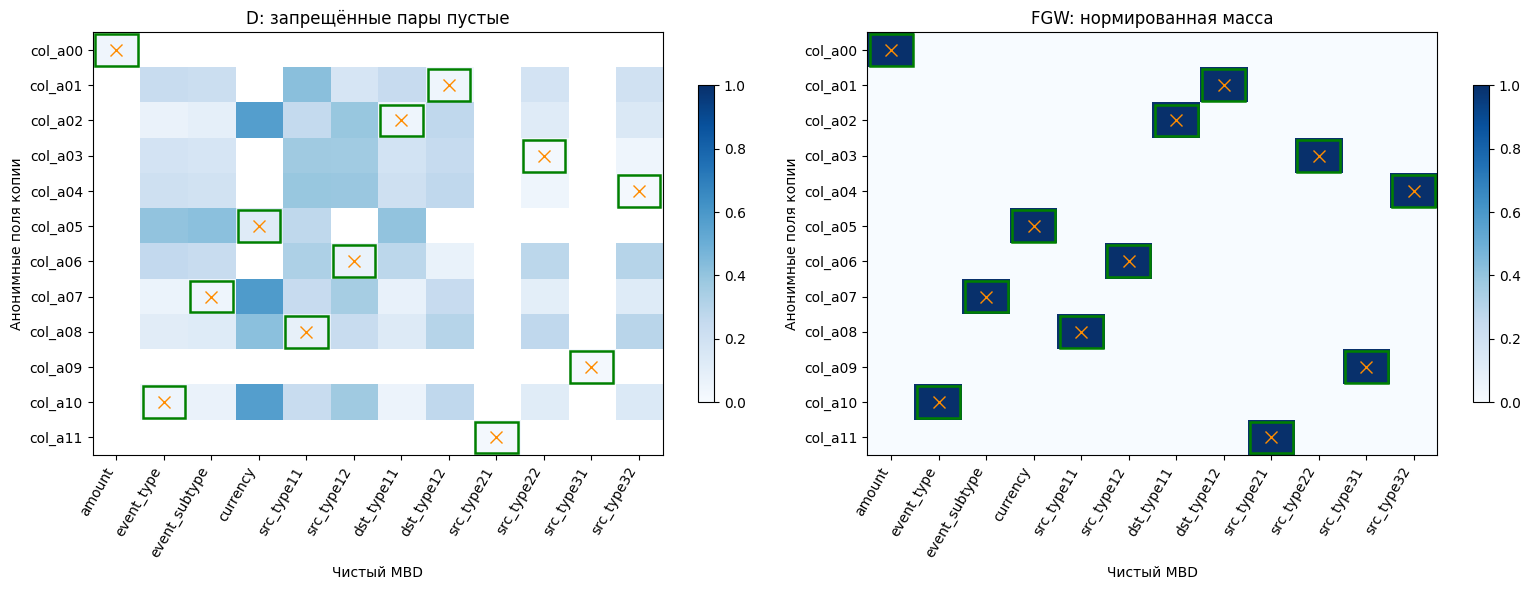

In [17]:
CASE = 'mixed_015/seed_0'
ALPHA = 0.5
selected = runs[(runs.case_id == CASE) & np.isclose(runs.alpha, ALPHA)]
if selected.empty:
    selected = runs.iloc[[0]]
record = selected.iloc[0]
run_dir = RESULTS / record.run_dir
recovery = pd.read_csv(run_dir / 'recovery.csv')
solver = json.loads((run_dir / 'solver.json').read_text())
print('Выбран:', record.case_id, 'alpha =', record.alpha)
display(recovery)
display(pd.DataFrame(solver['restarts']).drop(columns=['history', 'selected_source_indices'], errors='ignore'))

distance = pd.read_csv(run_dir / 'distance.csv', index_col='column')
allowed = pd.read_csv(run_dir / 'allowed_pairs.csv', index_col='column')
scores = pd.read_csv(run_dir / 'fgw_scores.csv', index_col='column')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, matrix, title in zip(axes, [distance.where(allowed), scores], ['D: запрещённые пары пустые', 'FGW: нормированная масса']):
    im = ax.imshow(matrix.to_numpy(dtype=float), vmin=0, vmax=1, cmap='Blues', aspect='auto')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=60, ha='right')
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(title=title, xlabel='Чистый MBD', ylabel='Анонимные поля копии')
    for item in recovery.itertuples():
        j = matrix.columns.get_loc(item.mbd_field)
        i = matrix.index.get_loc(item.truth)
        ax.add_patch(plt.Rectangle((j - 0.45, i - 0.45), 0.9, 0.9, fill=False, edgecolor='green', linewidth=1.8))
        if pd.notna(item.recovered):
            ax.plot(j, matrix.index.get_loc(item.recovered), marker='x', color='darkorange', markersize=9)
    fig.colorbar(im, ax=ax, shrink=0.75)
fig.tight_layout()
plt.show()
